In [2]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles
import matplotlib.pyplot as plt

In [4]:
np.random.seed(42)
X, Y = make_circles(n_samples=500, factor=0.1, noise=0.35, random_state=42)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2)

In [5]:
X.shape

(500, 2)

In [6]:
Y.shape

(500,)

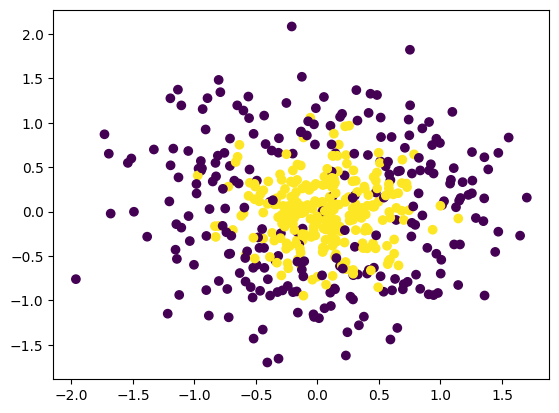

In [7]:
plt.scatter(X[:,0], X[:,1], c=Y)

In [8]:
from sklearn.tree import DecisionTreeClassifier

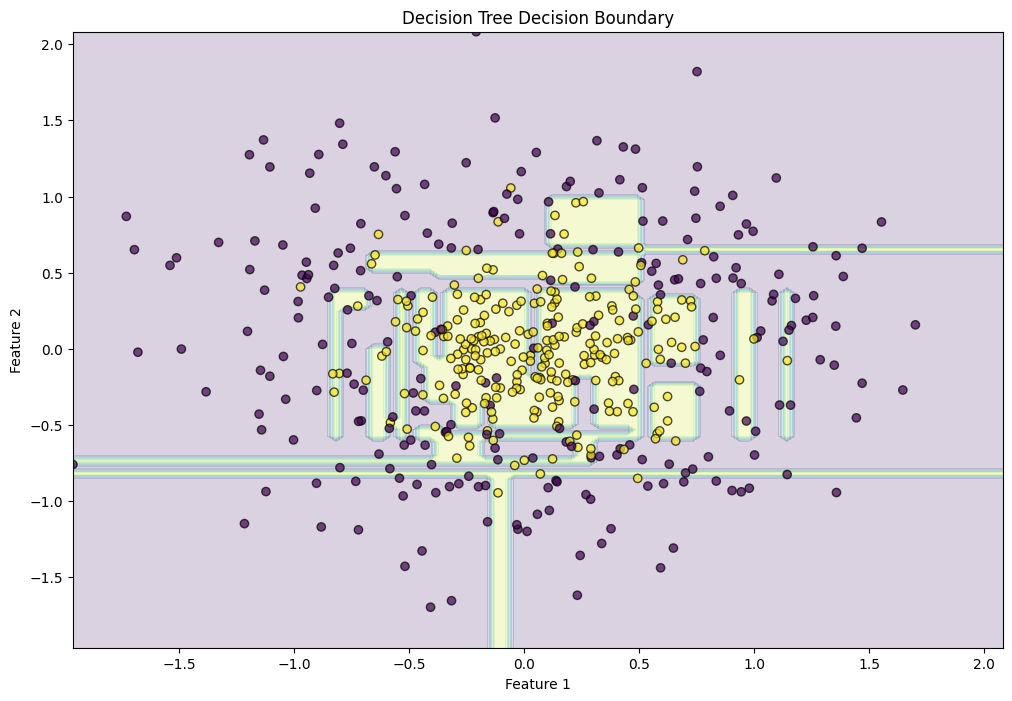

In [13]:
# Train decision tree
dt = DecisionTreeClassifier(random_state = 42)
dt.fit(X_train, Y_train)

# Create meshgrid
x_range = np.linspace(X.min(), X.max(), 100)
y_range = np.linspace(X[:,1].min(), X[:,1].max(), 100)
x1, x2 = np.meshgrid(x_range, x_range)

# Predict over meshgrid
y_hat = dt.predict(np.c_[x1.ravel(), x2.ravel()])   # x1.ravel() and x2.ravel() -> flatten the 2D meshgrid into 1D vectors.
y_hat = y_hat.reshape(x1.shape)

# Plot decision boundary
plt.figure(figsize=(12, 8))
plt.contourf(x1, x2, y_hat, alpha=0.2, cmap='viridis')
plt.scatter(X[:,0], X[:,1], c=Y, cmap='viridis', edgecolor='k', alpha=0.7)
plt.title('Decision Tree Decision Boundary')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Creating a Grid of Points** 

- np.linspace(start, stop, 100) → creates 100 evenly spaced points between the min and max of a feature.
- x_range → values along feature 1 (X-axis).
- y_range → values along feature 2 (Y-axis).
- np.meshgrid → combines them into a full grid of points (x1, x2) so we can cover the entire 2D feature space.


**Predicting the Class at Every Point in the Grid**

- x1.ravel() and x2.ravel() → flatten the 2D meshgrid into 1D vectors.
- np.c_[ ... ] → stacks them column-wise into (N, 2) shape (like test data).
- dt.predict(...) → predicts the class for each grid point.
- .reshape(x1.shape) → reshapes predictions back into a 2D grid so they match the mesh for plotting.


**Plotting the Decision Boundary**

- plt.contourf → fills regions of the plot with different colors depending on the predicted class (y_hat).
- alpha=0.2 → makes the background transparent (so points are visible).
- cmap='viridis' → sets the color palette.


**Plotting the Actual Dataset**

- X[:,0] → feature 1 values (X-axis).
- X[:,1] → feature 2 values (Y-axis).
- c=Y → color points based on their true class.
- edgecolor='k' → black border around points (makes them clearer).
- alpha=0.7 → makes points semi-transparent.

In [15]:
from sklearn.ensemble import RandomForestClassifier

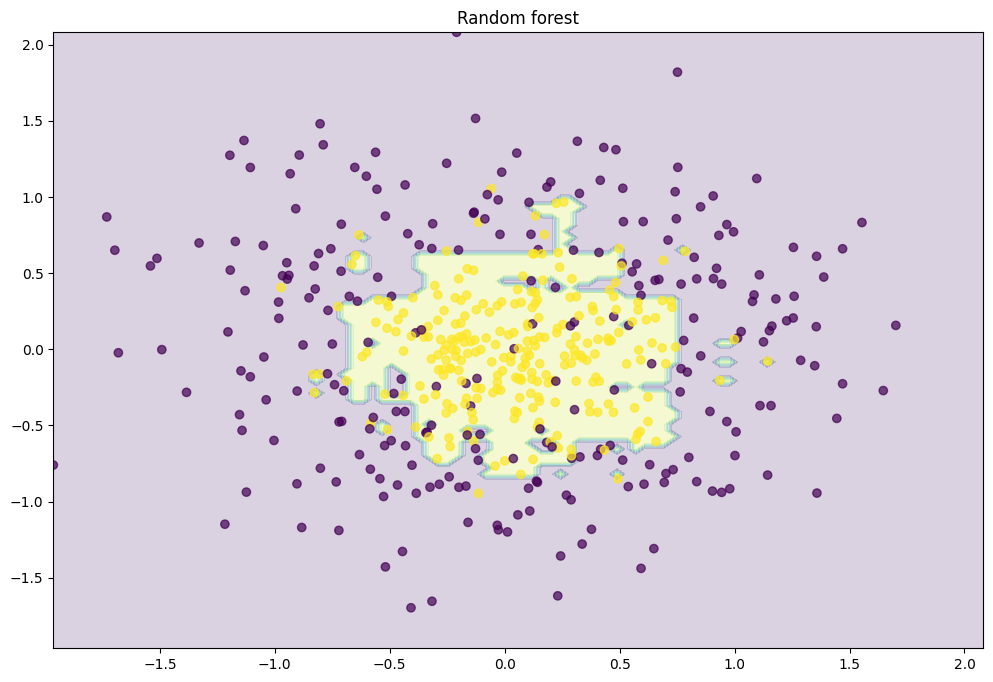

In [19]:
rf = RandomForestClassifier(n_estimators=500, random_state=42)
rf.fit(X_train, Y_train)

plt.figure(figsize=(12, 8))
x_range = np.linspace(X.min(), X.max(), 100)
x1, x2 = np.meshgrid(x_range, x_range)
y_hat = rf.predict(np.c_[x1.ravel(), x2.ravel()])
y_hat = y_hat.reshape(x1.shape)
plt.contourf(x1, x2, y_hat, alpha=0.2)
plt.scatter(X[:,0], X[:,1], c=Y, cmap='viridis', alpha=.7)
plt.title("Random forest")
plt.show()

In [20]:
n_train = 150        
n_test = 1000       
noise = 0.1

# Generate data
def f(x):
    x = x.ravel()
    return np.exp(-x ** 2) + 1.5 * np.exp(-(x - 2) ** 2)

def generate(n_samples, noise):
    X = np.random.rand(n_samples) * 10 - 5
    X = np.sort(X).ravel()
    y = np.exp(-X ** 2) + 1.5 * np.exp(-(X - 2) ** 2)\
        + np.random.normal(0.0, noise, n_samples)
    X = X.reshape((n_samples, 1))

    return X, y

X_train, y_train = generate(n_samples=n_train, noise=noise)
X_test, y_test = generate(n_samples=n_test, noise=noise)

(-5.0, 5.0)

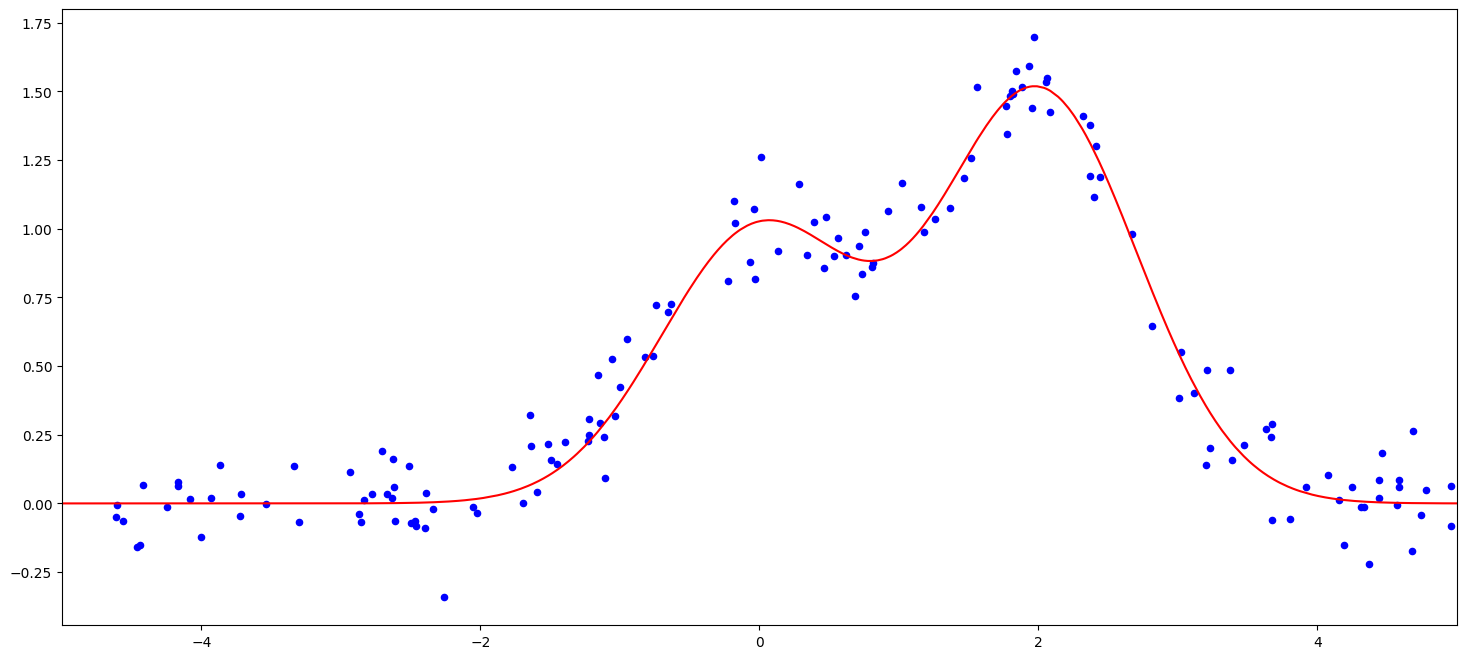

In [21]:
plt.figure(figsize=(18, 8))
plt.plot(X_test, f(X_test), "r")
plt.scatter(X_train, y_train, c="b", s=20)
plt.xlim([-5, 5])

Text(0.5, 1.0, 'Decision tree, MSE = 22.70')

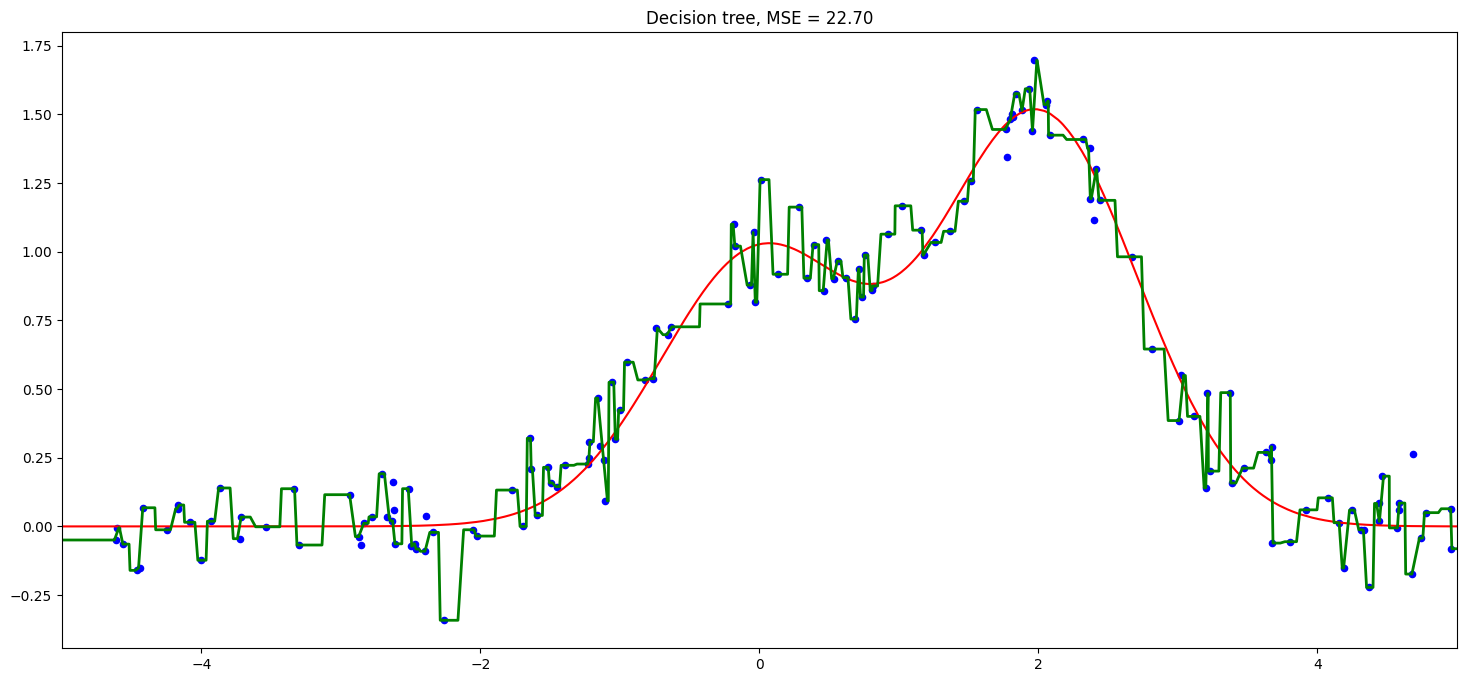

In [22]:
# One decision tree regressor
from sklearn.tree import DecisionTreeRegressor

dtree = DecisionTreeRegressor().fit(X_train, y_train)
d_predict = dtree.predict(X_test)

plt.figure(figsize=(18, 8))
plt.plot(X_test, f(X_test), "r")
plt.scatter(X_train, y_train, c="b", s=20)
plt.plot(X_test, d_predict, "g", lw=2)
plt.xlim([-5, 5])
plt.title("Decision tree, MSE = %.2f" 
          % np.sum((y_test - d_predict) ** 2))

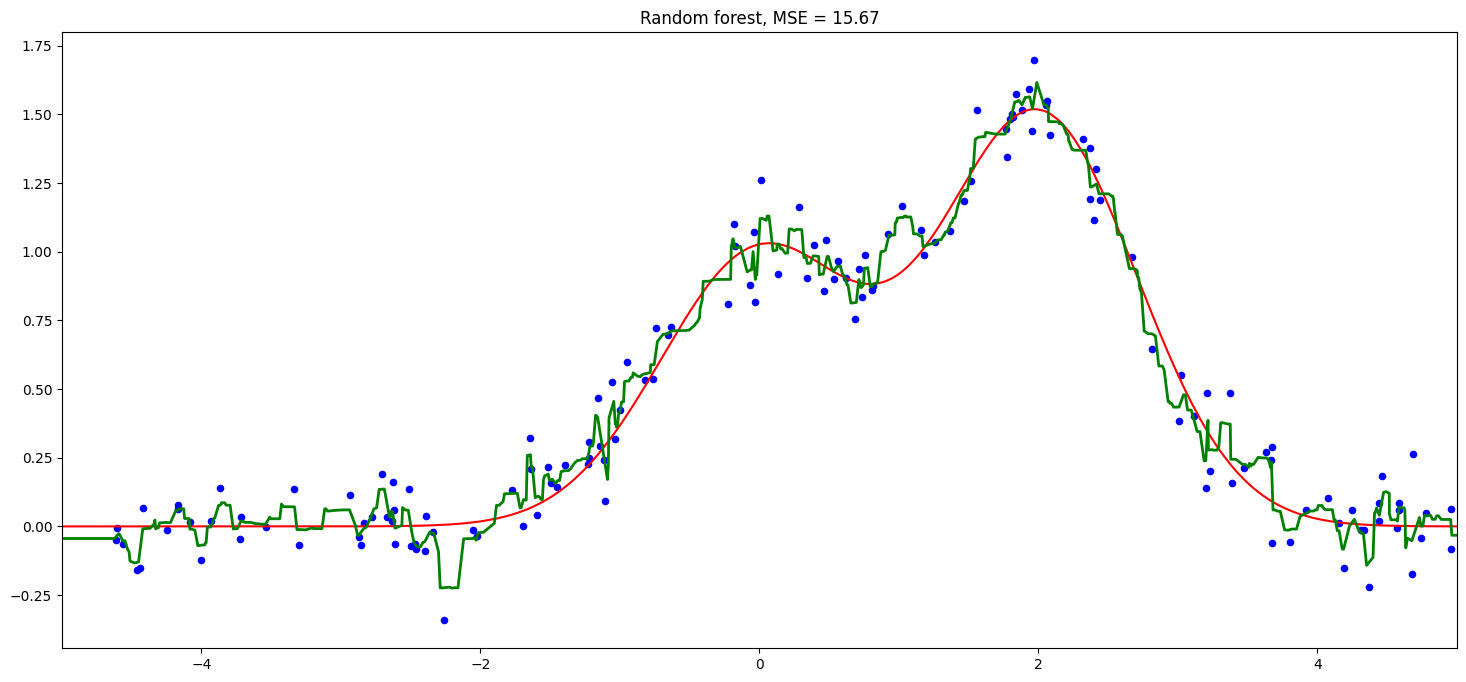

In [24]:
# Random Forest
from sklearn.ensemble import RandomForestRegressor

rfr = RandomForestRegressor(n_estimators=1000).fit(X_train, y_train)
rf_predict = rfr.predict(X_test)

plt.figure(figsize=(18, 8))
plt.plot(X_test, f(X_test), "r")
plt.scatter(X_train, y_train, c="b", s=20)
plt.plot(X_test, rf_predict, "g", lw=2)
plt.xlim([-5, 5])
plt.title("Random forest, MSE = %.2f" % np.sum((y_test - rf_predict)**2));